In [1]:
!pip -q install ultralytics scikit-learn pyyaml pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gnss-lib-py 1.0.4 requires pandas<3.0.0,>=2.0.0, but you have pandas 3.0.1 which is incompatible.

[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
#import libraries
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

In [ ]:
#Project Path
PROJECT_ROOT = Path("modules/Detection")
print("Project root:", PROJECT_ROOT)


Project root: ..\modules\Detection


In [13]:
# Dataset
DATASET_ROOT = PROJECT_ROOT / "dataset"
data = DATASET_ROOT / "data.yaml"
RUNS_PATH = PROJECT_ROOT / "runs"

In [17]:
#NOTE ELRIC: At this point, the frames have already been extracted, labeled, and split into train/val folders

#load the model
model = YOLO("yolo12s.pt")
#train the model
train_results = model.train(data=data,
epochs=5,
batch=8,
patience = 20,
project=RUNS_PATH,
name="yolov12s")

New https://pypi.org/project/ultralytics/8.4.152 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.235  Python-3.13.7 torch-2.9.1+cpu CPU (Intel Core Ultra 7 155H)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=..\modules\Detection\dataset\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov12s4, nbs=64, nms=False, op

# Percentage of MAP per detection model

In [ ]:
from pathlib import Path

runs_Path = Path(RUNS_PATH)

models = {
    "YOLO11n": runs_Path / "yolov11n" / "weights" / "best.pt",
    "YOLO11s": runs_Path / "yolov11s" / "weights" / "best.pt",
    "YOLO11m": runs_Path / "yolov11m" / "weights" / "best.pt",
    "YOLO12n": runs_Path / "yolov12n" / "weights" / "best.pt",
    "YOLO12s": runs_Path / "yolov12s" / "weights" / "best.pt",
    "YOLO12m": runs_Path / "yolov12m" / "weights" / "best.pt",
    "YOLO26n": runs_Path / "yolov26n" / "weights" / "best.pt",
    "YOLO26s": runs_Path / "yolov26s" / "weights" / "best.pt",
    "YOLO26m": runs_Path / "yolov26m" / "weights" / "best.pt",
}

iou_thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

rows = []

for model_name, weight_path in models.items():
    print(f"Evaluating {model_name}...")

    model = YOLO(str(weight_path))
    results = model.val(data=data)

    row = {
        "model": model_name,
        "precision": float(results.box.mp),
        "recall": float(results.box.mr),
        "mAP@0.5": float(results.box.map50),
        "mAP@0.5:0.95": float(results.box.map),
    }

    # AP at each IoU threshold for class 0 = bus
    for i, iou in enumerate(iou_thresholds):
        row[f"AP@{iou:.2f}"] = float(results.box.all_ap[0, i])

    rows.append(row)

df = pd.DataFrame(rows)

csv_path = runs_Path / "model_comparison_metrics.csv"
df.to_csv(csv_path, index=False)

print(df)
print(f"Saved CSV to: {csv_path}")

Evaluating YOLO11n...
Ultralytics 8.4.45 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 141.8±8.8 MB/s, size: 365.2 KB)
val: Scanning /content/drive/MyDrive/Final_Thesis/dataset/valid/labels.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 2.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.5it/s 0.2s
                   all          8         55      0.999          1      0.995      0.781
Speed: 1.1ms preprocess, 11.2ms inference, 0.0ms loss, 4.1ms postprocess per image
Results saved to /content/runs/detect/val
Evaluating YOLO11s...
Ultralytics 8.4.45 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 

# IOU Check


image 1/1 /content/drive/MyDrive/Final_Thesis/dataset/test/images/Balsta_1_trim_mp4-0013_jpg.rf.7aa80a12b8e66a66cfa9ef08a316d103.jpg: 384x640 5 buss, 56.0ms
Speed: 2.1ms preprocess, 56.0ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


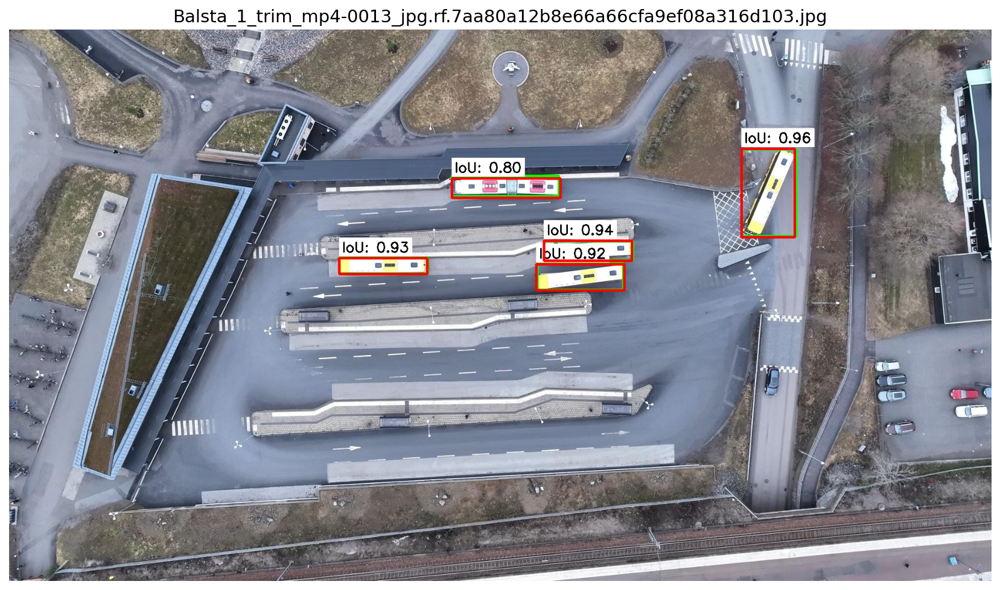


image 1/1 /content/drive/MyDrive/Final_Thesis/dataset/test/images/Balsta_1_trim_mp4-0015_jpg.rf.92bb3446b79f944b40962568fc596ede.jpg: 384x640 5 buss, 11.0ms
Speed: 3.2ms preprocess, 11.0ms inference, 1.7ms postprocess per image at shape (1, 3, 384, 640)


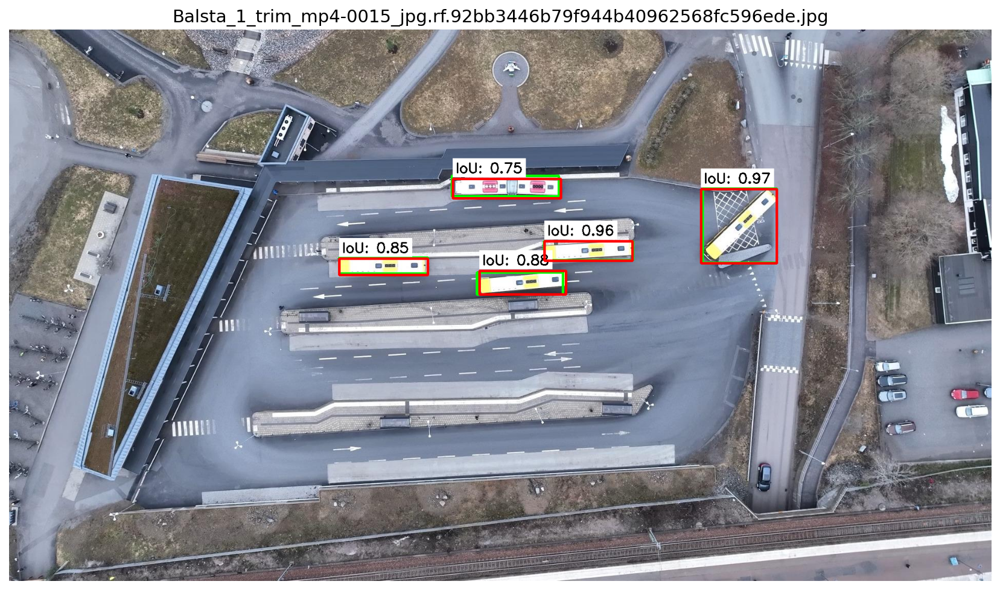


image 1/1 /content/drive/MyDrive/Final_Thesis/dataset/test/images/Balsta_1_trim_mp4-0037_jpg.rf.bf62bfc55af883c60207599a300917b8.jpg: 384x640 7 buss, 11.8ms
Speed: 3.1ms preprocess, 11.8ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


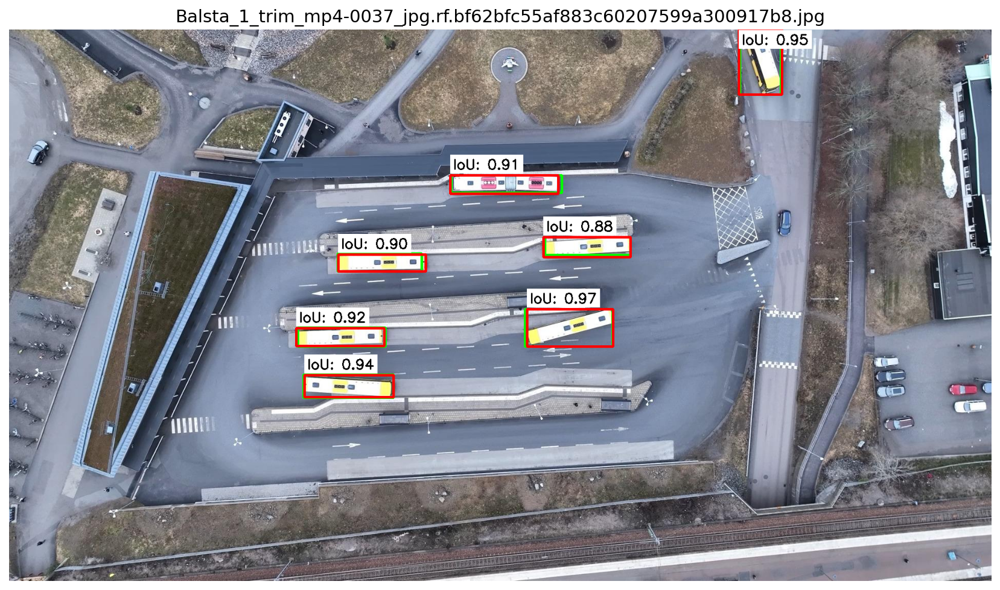


image 1/1 /content/drive/MyDrive/Final_Thesis/dataset/test/images/Balsta_1_trim_mp4-0120_jpg.rf.244982c0e6faca85185867408783a111.jpg: 384x640 9 buss, 11.5ms
Speed: 3.2ms preprocess, 11.5ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)


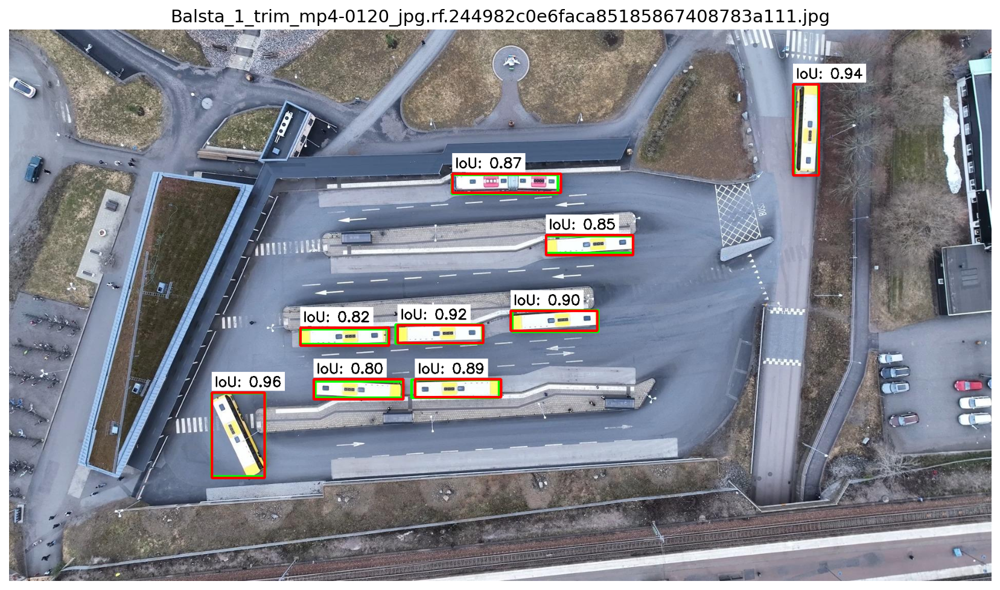

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Load model
model = YOLO(Path(RUNS_PATH) / "yolov11s" / "weights" / "best.pt")

# Paths
test_images_dir = Path(DATASET_ROOT)/"test/images"
test_labels_dir = Path(DATASET_ROOT)/"test/labels"

IMG_EXTS = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

# IoU function

def calculate_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    inter_area = max(0, xB - xA) * max(0, yB - yA)

    boxA_area = max(0, boxA[2] - boxA[0]) * max(0, boxA[3] - boxA[1])
    boxB_area = max(0, boxB[2] - boxB[0]) * max(0, boxB[3] - boxB[1])

    union_area = boxA_area + boxB_area - inter_area

    return inter_area / union_area if union_area > 0 else 0


# Read YOLO label boxes

def read_gt_boxes(label_path, img_w, img_h):
    gt_boxes = []

    if not label_path.exists():
        return gt_boxes

    with open(label_path, "r") as f:
        for line in f:
            values = line.strip().split()
            if len(values) < 5:
                continue

            cls, x, y, bw, bh = map(float, values[:5])

            x1 = int((x - bw / 2) * img_w)
            y1 = int((y - bh / 2) * img_h)
            x2 = int((x + bw / 2) * img_w)
            y2 = int((y + bh / 2) * img_h)

            gt_boxes.append([x1, y1, x2, y2])

    return gt_boxes


# Draw label with background

def draw_text_with_background(img, text, x, y):
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.9
    thickness = 2

    (tw, th), _ = cv2.getTextSize(text, font, font_scale, thickness)

    y = max(y, th + 10)

    cv2.rectangle(
        img,
        (x, y - th - 8),
        (x + tw + 10, y + 8),
        (255, 255, 255),
        -1
    )

    cv2.putText(
        img,
        text,
        (x + 5, y),
        font,
        font_scale,
        (0, 0, 0),
        thickness
    )


# Loop through test images

image_paths = []
for ext in IMG_EXTS:
    image_paths.extend(test_images_dir.glob(f"*{ext}"))

for img_path in sorted(image_paths):

    label_path = test_labels_dir / f"{img_path.stem}.txt"

    img = cv2.imread(str(img_path))
    if img is None:
        print(f"Could not read image: {img_path}")
        continue

    h, w = img.shape[:2]

    # Ground-truth boxes
    gt_boxes = read_gt_boxes(label_path, w, h)

    # YOLO predictions
    results = model(str(img_path), conf=0.25)[0]

    if results.boxes is not None:
        pred_boxes = results.boxes.xyxy.cpu().numpy().astype(int)
    else:
        pred_boxes = []

    # Draw ground-truth boxes in green
    for gt in gt_boxes:
        cv2.rectangle(
            img,
            (gt[0], gt[1]),
            (gt[2], gt[3]),
            (0, 255, 0),
            4
        )

    # Draw prediction boxes in red and IoU values
    for pred in pred_boxes:
        pred_box = pred.tolist()

        best_iou = 0
        for gt in gt_boxes:
            best_iou = max(best_iou, calculate_iou(gt, pred_box))

        x1, y1, x2, y2 = pred_box

        cv2.rectangle(
            img,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            4
        )

        draw_text_with_background(
            img,
            f"IoU: {best_iou:.2f}",
            x1,
            y1 - 12
        )

    # Show image
    plt.figure(figsize=(14, 10), dpi=150)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(img_path.name, fontsize=14)
    plt.axis("off")
    plt.show()